# Tree Models: Random Forest and Gradient Boosting

This notebook trains the two non-linear models for Remaining Useful Life (RUL): Random Forest and histogram gradient boosting. Both use the same rolling features, engine-level split, and fixed cutoff points as the linear baseline.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor

from load_data import load_test, load_train
from features import FEATURES, add_rolling_features
from evaluation import mae, rmse, split_train_val, test_points, validation_points

Matplotlib is building the font cache; this may take a moment.


## 1. Data

The validation and test scores use fixed engine-level points so every model is compared fairly.

In [2]:
train = add_rolling_features(load_train())
test = add_rolling_features(load_test())
train_df, val_df = split_train_val(train)
val_pts = validation_points(val_df)
test_pts = test_points(test)

print(f"Training rows: {len(train_df):,}; validation rows: {len(val_df):,}")
print(f"Validation points: {len(val_pts)}; test points: {len(test_pts)}")
print(f"Features: {len(FEATURES)}")

Training rows: 16,390; validation rows: 4,241
Validation points: 100; test points: 100
Features: 57


## 2. Two models

The models use the prescribed fixed settings and are fitted without scaling. `early_stopping=False` prevents gradient boosting from creating a random row holdout that could put cycles from the same engine on both sides.

In [3]:
rf = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=20,
    max_features=0.33,
    random_state=42,
    n_jobs=-1,
)
gb = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=200,
    max_depth=3,
    early_stopping=False,
    random_state=42,
)

for model in (rf, gb):
    model.fit(train_df[FEATURES], train_df["rul"])

## 3. Validation scores

Both models are scored at the 100 fixed validation cutoff points.

In [4]:
validation_scores = pd.DataFrame([
    {
        "model": "Random Forest",
        "MAE": mae(val_pts["rul"], rf.predict(val_pts[FEATURES])),
        "RMSE": rmse(val_pts["rul"], rf.predict(val_pts[FEATURES])),
    },
    {
        "model": "Gradient boosting",
        "MAE": mae(val_pts["rul"], gb.predict(val_pts[FEATURES])),
        "RMSE": rmse(val_pts["rul"], gb.predict(val_pts[FEATURES])),
    },
])
validation_scores

,model,MAE,RMSE
0,Random Forest,25.027359,40.166277
1,Gradient boosting,26.122967,40.167749


## 4. Fit check

Random Forest fits the training rows much better than validation (some overfitting), and boosting less so.

In [5]:
fit_check = pd.DataFrame([
    {
        "model": "Random Forest",
        "training_RMSE": rmse(train_df["rul"], rf.predict(train_df[FEATURES])),
        "validation_RMSE": rmse(val_df["rul"], rf.predict(val_df[FEATURES])),
    },
    {
        "model": "Gradient boosting",
        "training_RMSE": rmse(train_df["rul"], gb.predict(train_df[FEATURES])),
        "validation_RMSE": rmse(val_df["rul"], gb.predict(val_df[FEATURES])),
    },
])
fit_check

,model,training_RMSE,validation_RMSE
0,Random Forest,21.147426,42.617864
1,Gradient boosting,29.656988,43.021962


## 5. Predicted vs actual RUL

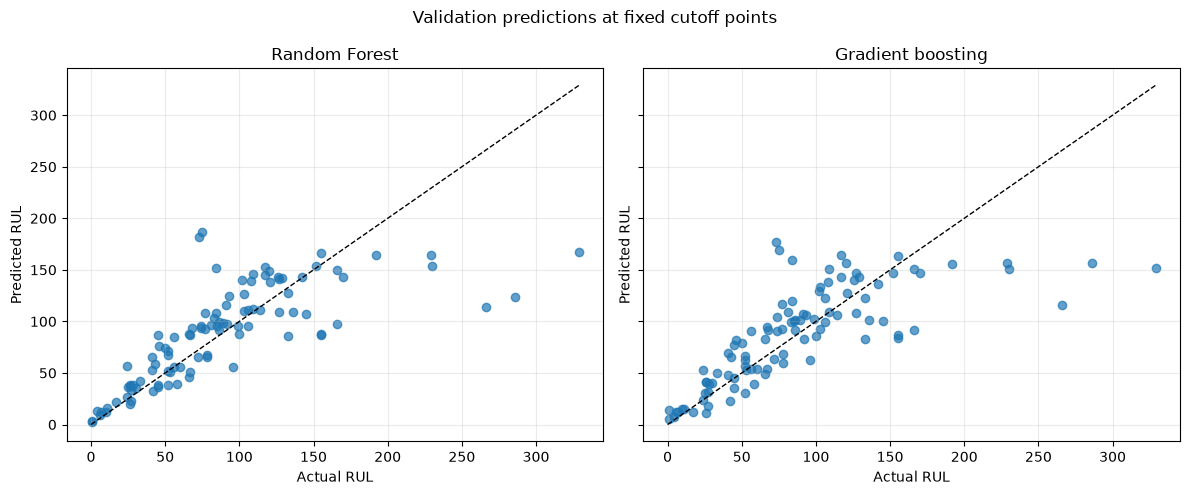

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, name, model in zip(axes, ["Random Forest", "Gradient boosting"], [rf, gb]):
    predictions = model.predict(val_pts[FEATURES])
    ax.scatter(val_pts["rul"], predictions, alpha=0.7)
    limit = max(val_pts["rul"].max(), predictions.max())
    ax.plot([0, limit], [0, limit], "k--", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("Actual RUL")
    ax.set_ylabel("Predicted RUL")
    ax.grid(alpha=0.25)
fig.suptitle("Validation predictions at fixed cutoff points")
fig.tight_layout()
plt.show()

## 6. Feature importance

`cycle` leads, followed by sensor rolling means. Importance shows what the model **uses**, not what **causes** failure, and correlated features share credit.

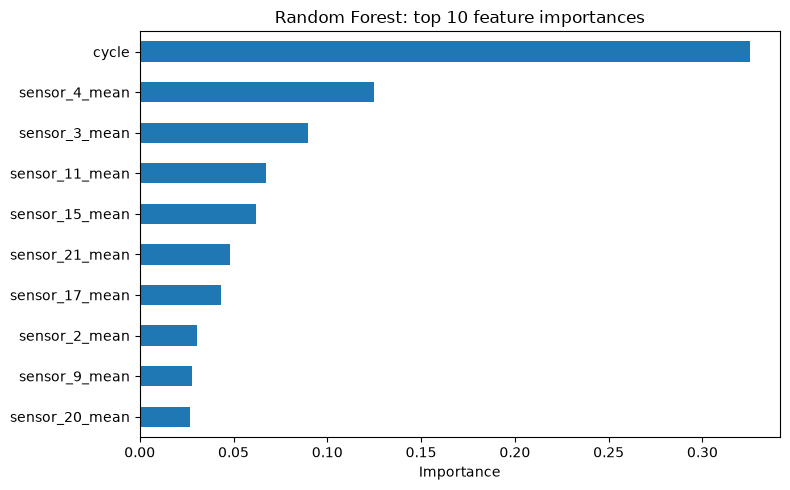

cycle             0.325098
sensor_4_mean     0.124986
sensor_3_mean     0.089791
sensor_11_mean    0.067301
sensor_15_mean    0.061996
sensor_21_mean    0.048133
sensor_17_mean    0.043469
sensor_2_mean     0.030590
sensor_9_mean     0.027992
sensor_20_mean    0.027023
dtype: float64

In [7]:
importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)
importance.head(10).sort_values().plot.barh(figsize=(8, 5), title="Random Forest: top 10 feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
importance.head(10)

## 7. Save predictions

There is no test scoring in this notebook; the final evaluation notebook scores these predictions against the supplied test RUL.

In [8]:
val_predictions = val_pts[["engine_id", "cycle"]].copy()
val_predictions["random_forest"] = rf.predict(val_pts[FEATURES])
val_predictions["gradient_boosting"] = gb.predict(val_pts[FEATURES])
val_predictions.to_csv("../results/val_predictions_trees.csv", index=False)

test_predictions = test_pts[["engine_id"]].copy()
test_predictions["random_forest"] = rf.predict(test_pts[FEATURES])
test_predictions["gradient_boosting"] = gb.predict(test_pts[FEATURES])
test_predictions.to_csv("../results/test_predictions_trees.csv", index=False)

print("Saved results/val_predictions_trees.csv", val_predictions.shape)
print("Saved results/test_predictions_trees.csv", test_predictions.shape)

Saved results/val_predictions_trees.csv (100, 4)
Saved results/test_predictions_trees.csv (100, 3)
